# Day 028 | SciPy — Interpolation & Curve Fitting

## 100 Days of ML for Geotechnical Engineering
**Phase:** Data Science Essentials

**Author:** Ripon Chandra Malo  
**Date:** March 14, 2026

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| **interp1d** | Interpolate between discrete measurements | N-value at 4.7m from samples at 3m and 6m |
| **CubicSpline** | Smooth C² curve through all data points | Continuous water content profile |
| **RegularGridInterpolator** | Interpolate on a 2D grid | Vs30 map across a construction site |
| **curve_fit** | Fit equation parameters to data | Calibrate Vs = a·N^b to local measurements |

---

## Our Geotechnical Problem

We have 8 SPT measurements at discrete depths (every 1.5 m) from BH-01. To run ML models and compute site amplification factors, we need soil properties at every 0.25 m. Today we use SciPy to fill the gaps — and fit the Imai & Tonouchi (1982) Vs–N power law to our local data.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d, CubicSpline, RegularGridInterpolator
from scipy.optimize import curve_fit

np.random.seed(42)
print('Libraries loaded.')
print('scipy version:', __import__('scipy').__version__)

Libraries loaded.
scipy version: 1.17.1


In [2]:
# ─────────────────────────────────────────────────────
# SPT BOREHOLE DATA — 8 measurements every 1.5 m
# ─────────────────────────────────────────────────────

depths_spt  = np.array([1.5, 3.0, 4.5, 6.0, 7.5, 9.0, 10.5, 12.0])
N_values    = np.array([  8,  12,  18,  22,  28,  35,   42,   50])
wc_values   = np.array([ 24,  21,  19,  17,  15,  13,   12,   11])  # water content %
uw_values   = np.array([17.5, 18.0, 18.5, 19.0, 19.5, 20.0, 20.5, 21.0])  # unit weight kN/m3

depths_fine = np.arange(1.5, 12.01, 0.25)  # 0.25 m grid
print(f'Measured depths   : {len(depths_spt)} points every 1.5 m')
print(f'Interpolation grid: {len(depths_fine)} points every 0.25 m  ({len(depths_fine)/len(depths_spt):.0f}x denser)')

Measured depths   : 8 points every 1.5 m
Interpolation grid: 43 points every 0.25 m  (5x denser)


## Part 1: interp1d — Three Interpolation Methods

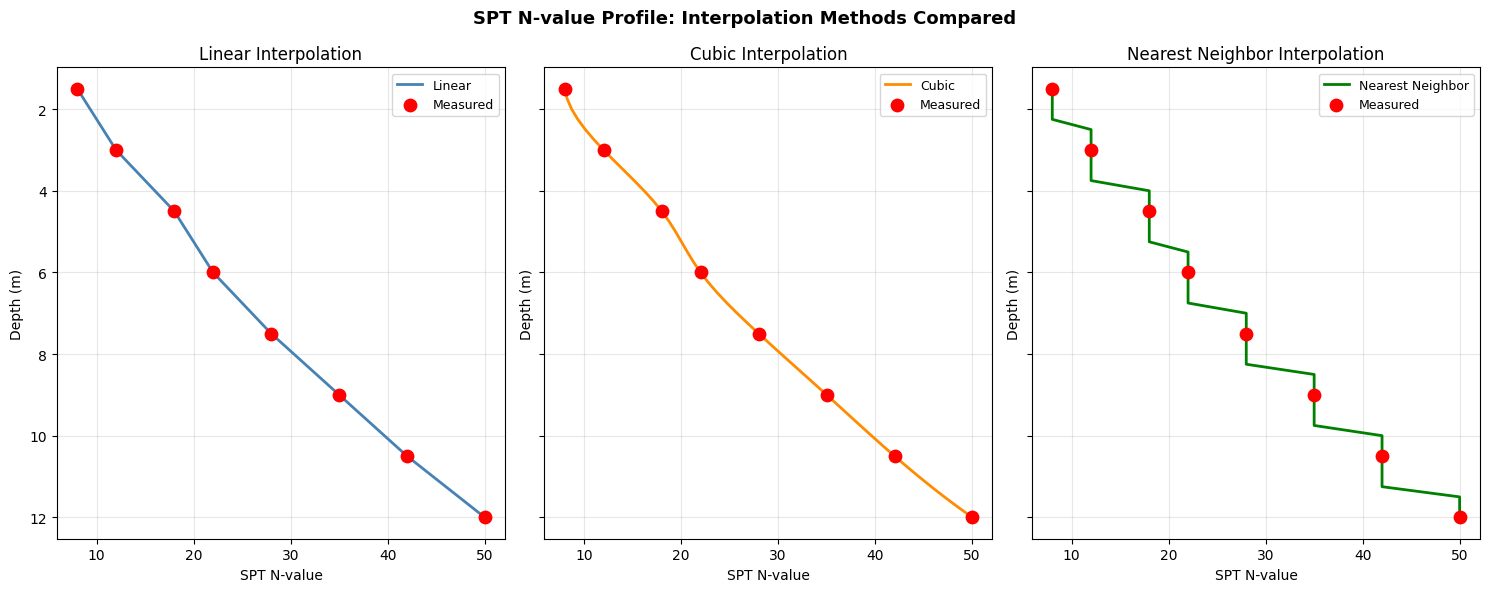

Use linear for quick estimates.
Use cubic for smooth, realistic engineering profiles.
Use nearest for categorical data (soil type labels).


In [3]:
# ─────────────────────────────────────────────────────
# interp1d: linear, cubic, nearest
# ─────────────────────────────────────────────────────

f_linear  = interp1d(depths_spt, N_values, kind='linear')
f_cubic   = interp1d(depths_spt, N_values, kind='cubic')
f_nearest = interp1d(depths_spt, N_values, kind='nearest')

N_linear  = f_linear(depths_fine)
N_cubic   = f_cubic(depths_fine)
N_nearest = f_nearest(depths_fine)

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
for ax, vals, title, color in zip(
    axes,
    [N_linear, N_cubic, N_nearest],
    ['Linear', 'Cubic', 'Nearest Neighbor'],
    ['steelblue', 'darkorange', 'green']
):
    ax.plot(vals, depths_fine, color=color, lw=2, label=title)
    ax.scatter(N_values, depths_spt, color='red', s=80, zorder=5, label='Measured')
    ax.invert_yaxis()
    ax.set_xlabel('SPT N-value')
    ax.set_ylabel('Depth (m)')
    ax.set_title(f'{title} Interpolation')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('SPT N-value Profile: Interpolation Methods Compared', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Use linear for quick estimates.')
print('Use cubic for smooth, realistic engineering profiles.')
print('Use nearest for categorical data (soil type labels).')

## Part 2: CubicSpline — Engineering-Grade Profiles

`CubicSpline` guarantees **C² continuity** (smooth first and second derivatives) — more physically realistic than piecewise linear. It also lets you compute the derivative of the profile (rate of change with depth).

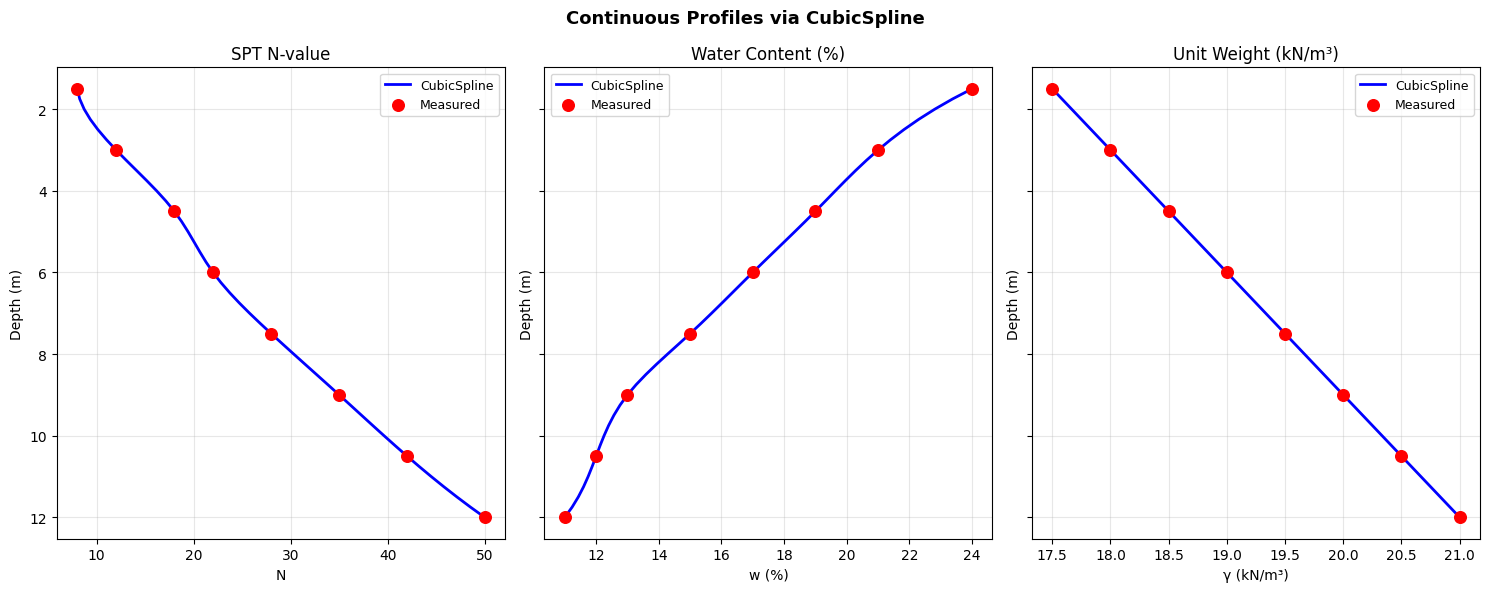

N at 5.25 m (interpolated): 20.0
Water content at 8.0 m:     14.3 %
dN/dz at 6.0 m:             3.05 per meter


In [4]:
# ─────────────────────────────────────────────────────
# CubicSpline: N, water content, unit weight profiles
# ─────────────────────────────────────────────────────

cs_N  = CubicSpline(depths_spt, N_values)
cs_wc = CubicSpline(depths_spt, wc_values)
cs_uw = CubicSpline(depths_spt, uw_values)

N_fine  = np.clip(cs_N(depths_fine), 1, 100)
wc_fine = np.clip(cs_wc(depths_fine), 0, 50)
uw_fine = np.clip(cs_uw(depths_fine), 15, 25)

# Derivative: rate of N increase with depth
dN_dz = cs_N(depths_fine, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
for ax, fine, meas, title, xlabel in zip(
    axes,
    [N_fine, wc_fine, uw_fine],
    [N_values, wc_values, uw_values],
    ['SPT N-value', 'Water Content (%)', 'Unit Weight (kN/m³)'],
    ['N', 'w (%)', 'γ (kN/m³)']
):
    ax.plot(fine, depths_fine, 'b-', lw=2, label='CubicSpline')
    ax.scatter(meas, depths_spt, color='red', s=70, zorder=5, label='Measured')
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Depth (m)')
    ax.set_title(title)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Continuous Profiles via CubicSpline', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'N at 5.25 m (interpolated): {cs_N(5.25):.1f}')
print(f'Water content at 8.0 m:     {cs_wc(8.0):.1f} %')
print(f'dN/dz at 6.0 m:             {cs_N(6.0, 1):.2f} per meter')

## Part 3: RegularGridInterpolator — 2D Site Map

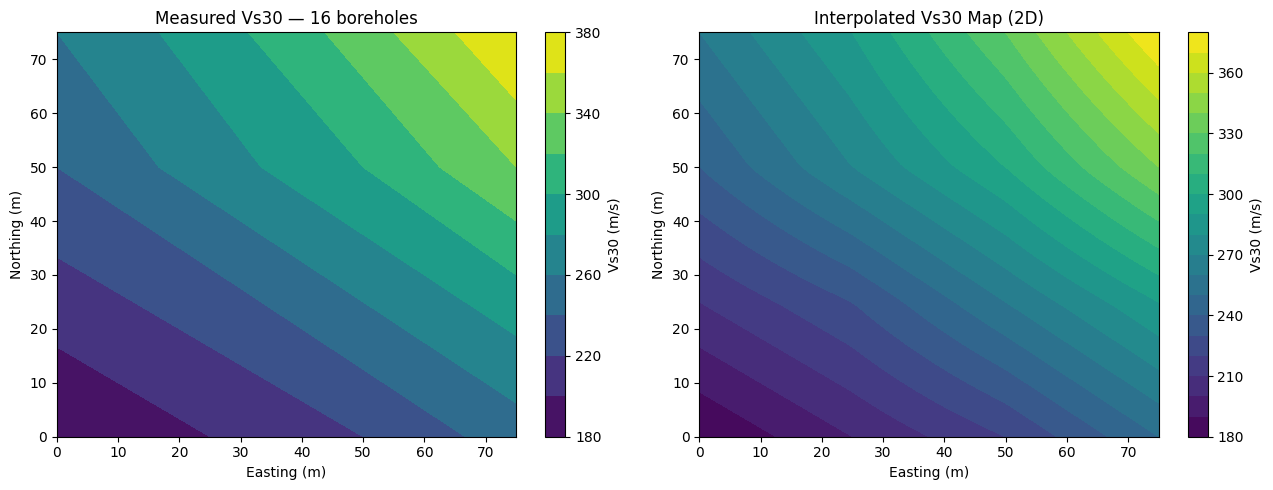

Vs30 at (35m E, 40m N): 266 m/s
ASCE 7 Site Class: D


In [5]:
# ─────────────────────────────────────────────────────
# 2D interpolation: Vs30 map from 4×4 borehole grid
# ─────────────────────────────────────────────────────

x_coords = np.array([0, 25, 50, 75])   # Easting (m)
y_coords = np.array([0, 25, 50, 75])   # Northing (m)

Vs30_grid = np.array([
    [180, 210, 240, 260],
    [200, 230, 270, 290],
    [220, 260, 300, 330],
    [250, 290, 340, 380]
], dtype=float)

interpolator = RegularGridInterpolator((x_coords, y_coords), Vs30_grid)

# Fine grid for plotting
xi = np.linspace(0, 75, 50)
yi = np.linspace(0, 75, 50)
XX, YY = np.meshgrid(xi, yi)
pts    = np.column_stack([XX.ravel(), YY.ravel()])
Vs_map = interpolator(pts).reshape(XX.shape)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
im1 = axes[0].contourf(x_coords, y_coords, Vs30_grid.T, levels=10, cmap='viridis')
axes[0].set_title('Measured Vs30 — 16 boreholes')
axes[0].set_xlabel('Easting (m)'); axes[0].set_ylabel('Northing (m)')
plt.colorbar(im1, ax=axes[0], label='Vs30 (m/s)')

im2 = axes[1].contourf(xi, yi, Vs_map, levels=20, cmap='viridis')
axes[1].set_title('Interpolated Vs30 Map (2D)')
axes[1].set_xlabel('Easting (m)'); axes[1].set_ylabel('Northing (m)')
plt.colorbar(im2, ax=axes[1], label='Vs30 (m/s)')

plt.tight_layout()
plt.show()

test_pt = np.array([[35, 40]])
Vs_pt   = interpolator(test_pt)[0]
print(f'Vs30 at (35m E, 40m N): {Vs_pt:.0f} m/s')
sc = 'C' if Vs_pt > 360 else ('D' if Vs_pt > 180 else 'E')
print(f'ASCE 7 Site Class: {sc}')

## Part 4: curve_fit — Fitting the Imai & Tonouchi Correlation

Imai & Tonouchi (1982): $V_s = a \cdot N^b$  
Published values: a = 97, b = 0.314  
We use `curve_fit` to calibrate a and b to **our site's data**.

Published (Imai 1982): Vs = 97.0 × N^0.314
Site-calibrated:       Vs = 99.0 × N^0.308
  a = 99.03 ± 4.53
  b = 0.308 ± 0.014


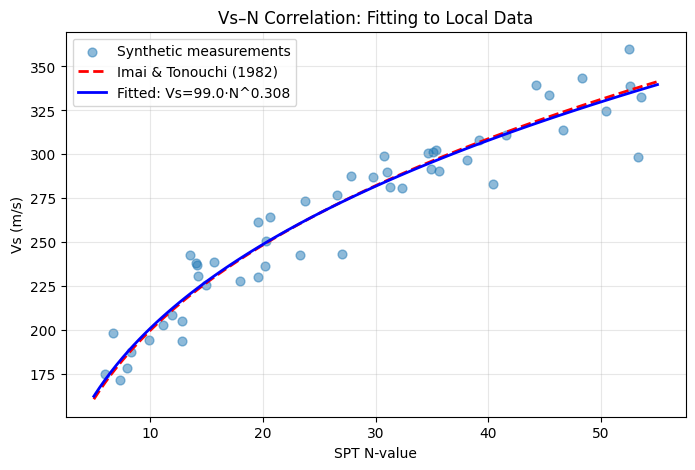

In [6]:
# ─────────────────────────────────────────────────────
# CURVE FITTING: power-law Vs = a * N^b
# ─────────────────────────────────────────────────────

def power_law(N, a, b):
    return a * N**b

N_data  = np.random.uniform(5, 55, 50)
Vs_data = 97 * N_data**0.314 + np.random.normal(0, 15, 50)

popt, pcov = curve_fit(power_law, N_data, Vs_data, p0=[100, 0.3])
a_fit, b_fit = popt
a_std, b_std = np.sqrt(np.diag(pcov))

print(f'Published (Imai 1982): Vs = 97.0 × N^0.314')
print(f'Site-calibrated:       Vs = {a_fit:.1f} × N^{b_fit:.3f}')
print(f'  a = {a_fit:.2f} ± {a_std:.2f}')
print(f'  b = {b_fit:.3f} ± {b_std:.3f}')

N_range = np.linspace(5, 55, 100)
plt.figure(figsize=(8, 5))
plt.scatter(N_data, Vs_data, alpha=0.5, s=40, label='Synthetic measurements')
plt.plot(N_range, 97 * N_range**0.314, 'r--', lw=2, label='Imai & Tonouchi (1982)')
plt.plot(N_range, power_law(N_range, *popt), 'b-', lw=2,
         label=f'Fitted: Vs={a_fit:.1f}·N^{b_fit:.3f}')
plt.xlabel('SPT N-value'); plt.ylabel('Vs (m/s)')
plt.title('Vs–N Correlation: Fitting to Local Data')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

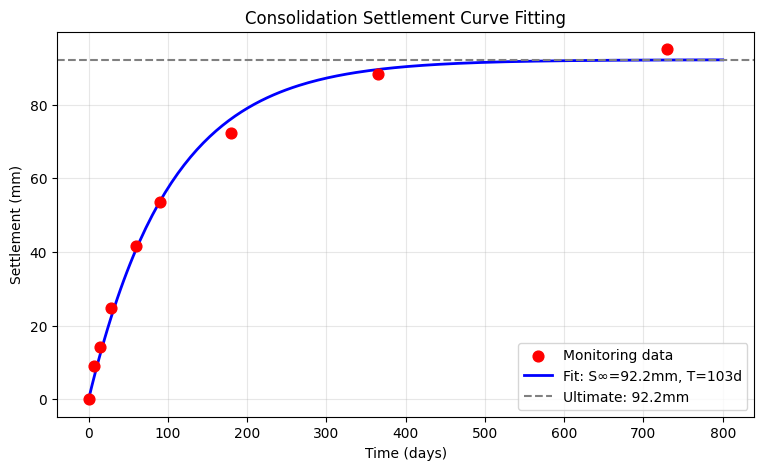

Ultimate settlement : 92.2 mm
Time constant T     : 103 days
Time for 90% consol.: 237 days


In [7]:
# ─────────────────────────────────────────────────────
# CURVE FITTING: consolidation settlement S(t) = Sf*(1 - exp(-t/T))
# ─────────────────────────────────────────────────────

def settlement_model(t, S_final, T):
    return S_final * (1 - np.exp(-t / T))

time_days = np.array([0, 7, 14, 28, 60, 90, 180, 365, 730])
S_obs = np.array([0, 8, 15, 25, 42, 55, 72, 88, 95]) + np.random.normal(0, 1, 9)

popt2, _ = curve_fit(settlement_model, time_days, S_obs,
                     p0=[100, 200], bounds=([0, 0], [300, 1000]))
S_final_fit, T_fit = popt2

t_range = np.linspace(0, 800, 200)
plt.figure(figsize=(9, 5))
plt.scatter(time_days, S_obs, color='red', s=60, zorder=5, label='Monitoring data')
plt.plot(t_range, settlement_model(t_range, *popt2), 'b-', lw=2,
         label=f'Fit: S∞={S_final_fit:.1f}mm, T={T_fit:.0f}d')
plt.axhline(S_final_fit, color='gray', ls='--', label=f'Ultimate: {S_final_fit:.1f}mm')
plt.xlabel('Time (days)'); plt.ylabel('Settlement (mm)')
plt.title('Consolidation Settlement Curve Fitting')
plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

print(f'Ultimate settlement : {S_final_fit:.1f} mm')
print(f'Time constant T     : {T_fit:.0f} days')
print(f'Time for 90% consol.: {-T_fit * np.log(0.1):.0f} days')

## Part 5: Complete Application — Full Borehole Profile

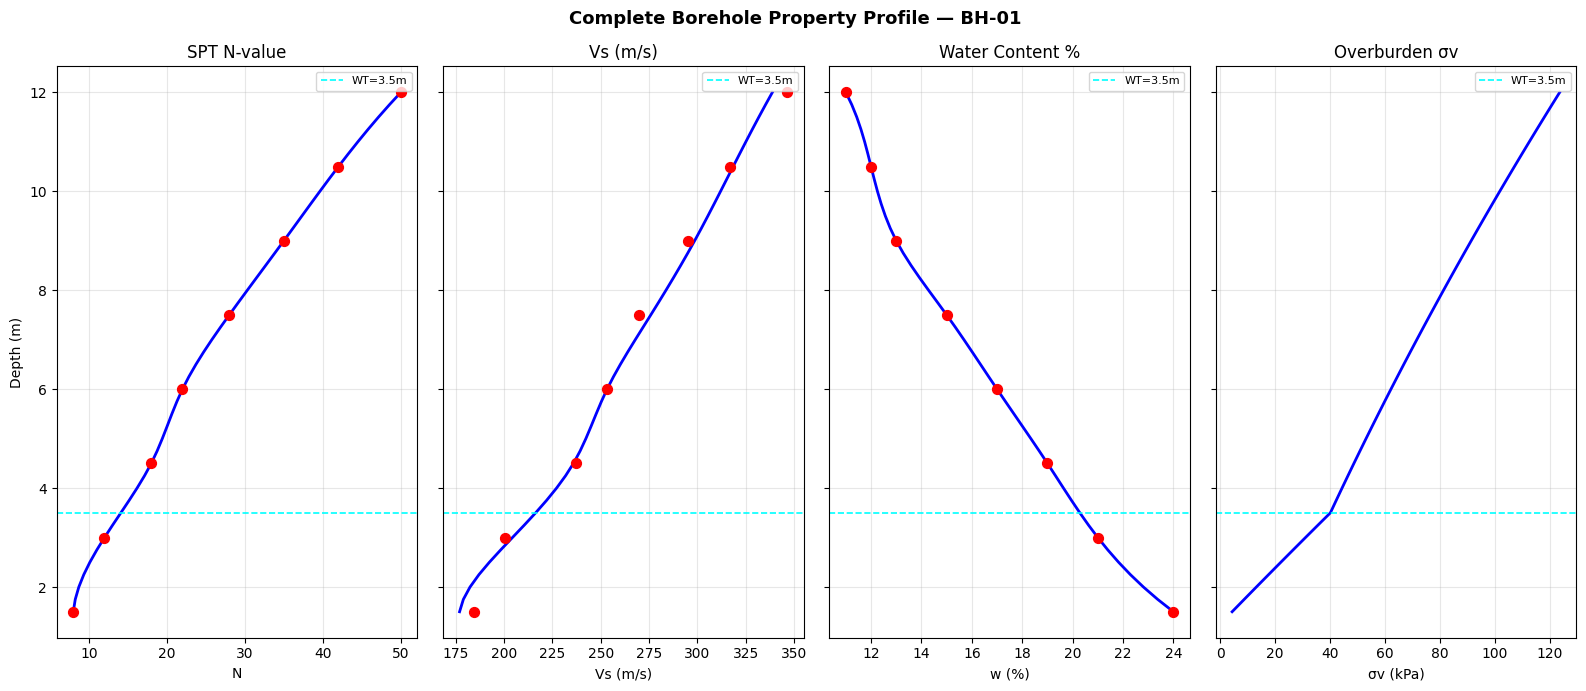

Profile at key depths:
  3.0m → N=12, Vs=204m/s, w=21.0%, σv=31.1kPa
  6.0m → N=22, Vs=253m/s, w=17.0%, σv=62.2kPa
  9.0m → N=35, Vs=299m/s, w=13.0%, σv=91.4kPa
  12.0m → N=50, Vs=339m/s, w=11.0%, σv=123.6kPa


In [8]:
# ═══════════════════════════════════════════════════════
# COMPLETE PROFILE: interpolate all properties, compute Vs
# ═══════════════════════════════════════════════════════

water_table = 3.5  # m

cs_N2  = CubicSpline(depths_spt, N_values)
cs_wc2 = CubicSpline(depths_spt, wc_values)
cs_uw2 = CubicSpline(depths_spt, uw_values)

Vs_meas = 97 * N_values**0.314 + np.random.normal(0, 8, len(N_values))
popt_vs, _ = curve_fit(power_law, N_values, Vs_meas, p0=[97, 0.3])

d = depths_fine
N_p  = np.clip(cs_N2(d), 1, 100)
wc_p = np.clip(cs_wc2(d), 0, 50)
uw_p = np.clip(cs_uw2(d), 15, 25)
Vs_p = power_law(N_p, *popt_vs)

sat_mask = d > water_table
uw_eff   = np.where(sat_mask, uw_p - 9.81, uw_p)
sigma_v  = np.cumsum(uw_eff * 0.25)

fig, axes = plt.subplots(1, 4, figsize=(16, 7), sharey=True)
for ax, ydata, meas_y, meas_d, title, xlabel in zip(
    axes,
    [N_p, Vs_p, wc_p, sigma_v],
    [N_values, Vs_meas, wc_values, None],
    [depths_spt]*3 + [None],
    ['SPT N-value', 'Vs (m/s)', 'Water Content %', 'Overburden σv'],
    ['N', 'Vs (m/s)', 'w (%)', 'σv (kPa)']
):
    ax.plot(ydata, d, 'b-', lw=2)
    if meas_y is not None:
        ax.scatter(meas_y, meas_d, color='red', s=50, zorder=5)
    ax.axhline(water_table, color='cyan', ls='--', lw=1.2, label=f'WT={water_table}m')
    ax.invert_yaxis()
    ax.set_xlabel(xlabel); ax.set_title(title)
    if ax == axes[0]:
        ax.set_ylabel('Depth (m)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle('Complete Borehole Property Profile — BH-01', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Profile at key depths:')
for depth in [3.0, 6.0, 9.0, 12.0]:
    idx = np.argmin(np.abs(d - depth))
    print(f'  {depth:.1f}m → N={N_p[idx]:.0f}, Vs={Vs_p[idx]:.0f}m/s, w={wc_p[idx]:.1f}%, σv={sigma_v[idx]:.1f}kPa')

## Practice Exercises

### Exercise 1
A measurement at 6.0m is missing. Use `interp1d(kind='cubic')` on the remaining 7 points to estimate N at 6.0m.

### Exercise 2
Fit a linear relationship `N = a + b × depth` and compare its R² to the power-law Vs fit.

### Exercise 3
Use `RegularGridInterpolator` to query Vs30 at 5 new (x, y) coordinates across the site and classify each by ASCE 7 site class.

---

## Key Takeaways

1. **`interp1d`**: quick 1D interpolation. Use `kind='cubic'` for smooth profiles, `kind='nearest'` for categorical labels.
2. **`CubicSpline`**: C² continuous — the engineering-grade choice. Can also compute derivatives (profile gradients).
3. **`RegularGridInterpolator`**: 2D (and nD) grid interpolation — essential for site maps of Vs30, settlement, or any spatially varying parameter.
4. **`curve_fit`**: calibrate any empirical formula to local data. Always check uncertainty (±1σ) from `pcov`.
5. Always **clip** interpolated values to physically valid ranges — splines can extrapolate to nonsensical values outside the data bounds.

## How This Connects to ML

| Today | In ML (Phase 3–5) |
|-------|-------------------|
| CubicSpline profile | Continuous depth feature for LSTM / CNN input |
| curve_fit calibration | Baseline empirical model to compare against ML |
| 2D interpolation map | Spatial features for site classification models |
| 0.25 m profiles | Uniform-length sequences for deep learning |

---

*Day 028 of 100 — Now your data flows smoothly between the dots!*